# 02 — Estudo de experiência

**Pergunta.** O que os dados mostram, antes de qualquer modelo? Onde a mortalidade observada se afasta da
esperada, e em quanto?

O estudo de experiência é a primeira leitura, **univariada**: para cada variável, a razão entre óbitos
observados e esperados,

$$
\frac{A}{E} = \frac{\sum_c O_c}{\sum_c E_c},
$$

com intervalo de 95% exato (Garwood) para a contagem de óbitos. Ele mostra **onde** olhar; o modelo da
Etapa 3 separa efeitos que aqui aparecem misturados.

**Três fontes, todas usadas pelo mesmo código (`vgpricing.estudo`):**

| Parte | Fonte | Real? | Para que serve |
|---|---|---|---|
| A | SOA 2016 Group Term Life Mortality Study (EUA, 2010–2013) | real | estrutura da mortalidade em vida em grupo (capital, salário, atividade, porte) |
| B | SUSEP SES, ramo 0993 (Brasil) | real | nível de sinistralidade do mercado brasileiro e dispersão entre seguradoras |
| C | Carteira da seguradora (aqui, sintética) | sintética | o estudo que a área roda todo ano sobre a própria carteira |

Os arquivos públicos são preparados por `scripts/preparar_dados_publicos.py` (veja o README).

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from vgpricing.config import carregar_config
from vgpricing.tabua import obter_tabua
from vgpricing import publicos as P, estudo as S, manual as M
from vgpricing.graficos import estilo
estilo()

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
cfg, cp, cm = carregar_config("base", RAIZ), carregar_config("publicos", RAIZ), carregar_config("manual", RAIZ)
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=".*coluna lx.*")
    tabua = obter_tabua(cfg, RAIZ)
soa = P.ler_soa(cp, RAIZ)
ses = P.ler_ses(cp, RAIZ)
print(f"SOA: {len(soa):,} células | {soa['vidas_ano'].sum() / 1e6:.1f} milhões de vidas-ano | {soa['obitos'].sum():,} óbitos")
print(f"SES: {len(ses):,} linhas | {ses['competencia'].min():%m/%Y} a {ses['competencia'].max():%m/%Y}")

SOA: 418,412 células | 44.5 milhões de vidas-ano | 96,889 óbitos
SES: 74,006 linhas | 09/2000 a 07/2026


## A. Estrutura da mortalidade em vida em grupo (SOA, dados reais dos EUA)

**Base de comparação.** Nesta base, os esperados são as taxas do próprio estudo por idade e sexo; por isso o
A/E total é 100% e cada A/E mede o desvio de um segmento em relação à média do estudo, já descontados idade e
sexo.

### A.1 Conferência da extração

Antes de usar os dados, a extração tem de reproduzir o que a SOA publicou (relatório de 2016, exhibit 1.10,
A/E por valor por faixa de capital).

In [2]:
publicado = [129.7, 124.6, 108.0, 101.3, 89.5, 77.9, 62.1, 54.1, 48.1, 51.6, 172.6]
t = S.tabela_ae(soa, "faixa_capital", obs_valor="valor_obitos", esp_valor="esperados_v")
t = t[t["esperados_v"] > 0].reset_index(drop=True)
pd.DataFrame({"faixa de capital (US$ mil)": t["faixa_capital"], "A/E por valor (nosso)": (100 * t["ae_valor"]).round(1),
              "publicado pela SOA": publicado}).set_index("faixa de capital (US$ mil)")

,A/E por valor (nosso),publicado pela SOA
faixa de capital (US$ mil),,
A. < 25,129.700,129.700
B. 25-49,124.600,124.600
C. 50-74,108.000,108.000
D. 75-99,101.300,101.300
E. 100-149,89.500,89.500
F. 150-249,77.900,77.900
G. 250-499,62.100,62.100
H. 500-749,54.100,54.100
I. 750-999,48.100,48.100


Reprodução exata (o mesmo vale para salário e porte; o teste automático `tests/test_publicos.py` confere as
três tabelas).

### A.2 A/E por variável

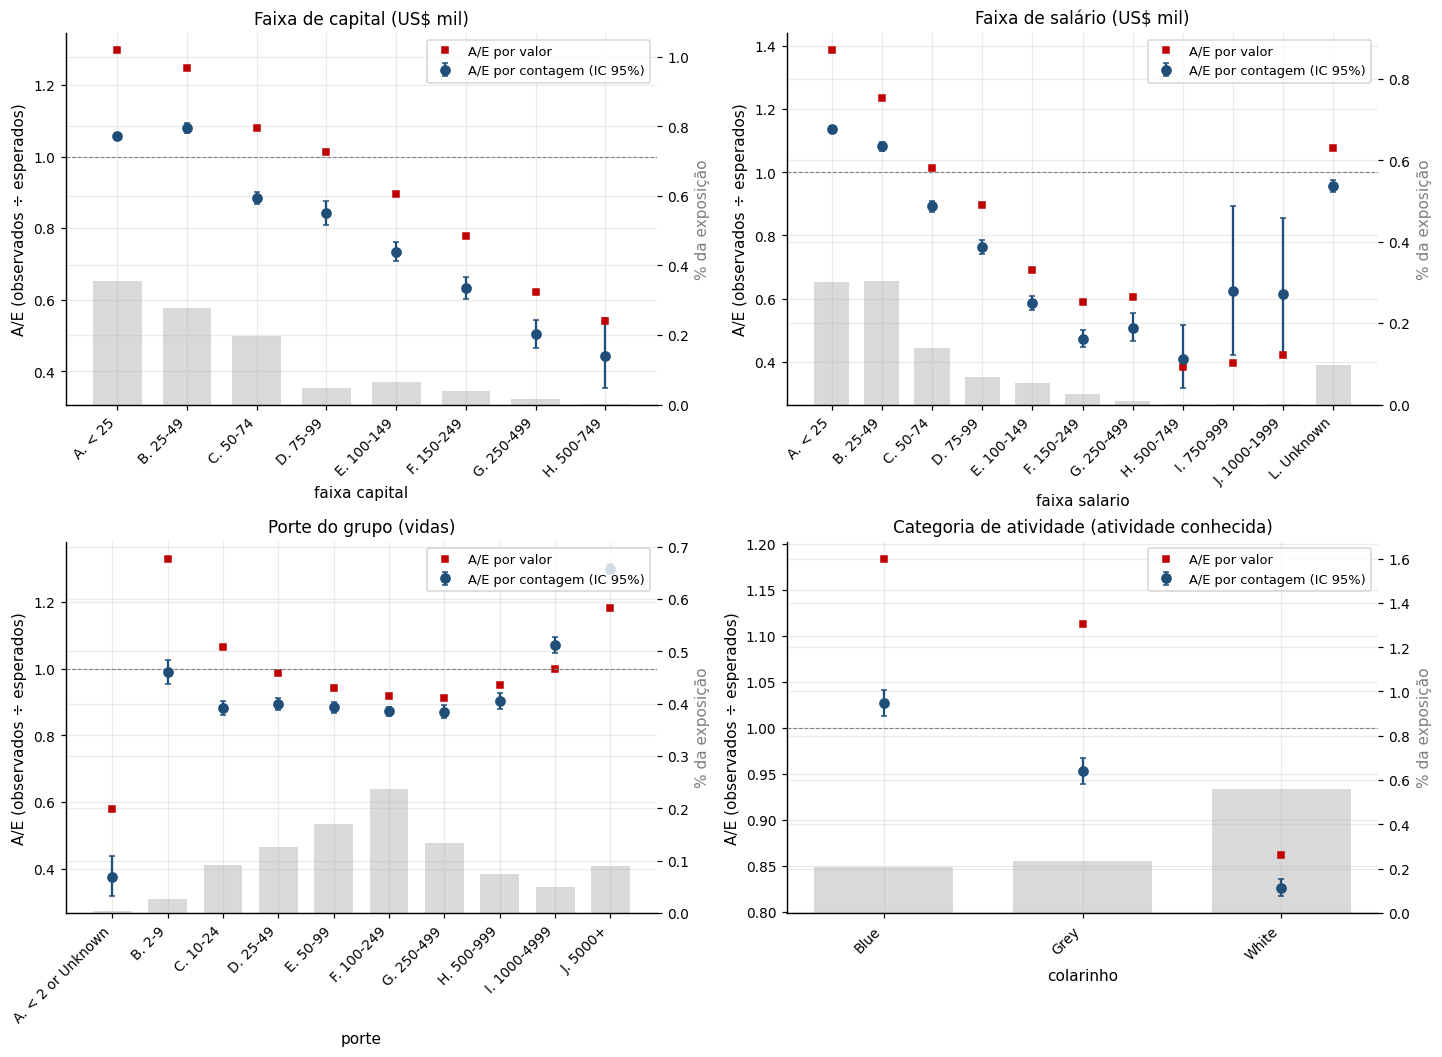

In [3]:
conhecida = soa[~soa["atividade"].astype(str).str.startswith("Z")]   # sem a atividade desconhecida (ver abaixo)
fig, axs = plt.subplots(2, 2, figsize=(13, 9.5))
for ax, (var, titulo, base) in zip(axs.flat, [("faixa_capital", "Faixa de capital (US$ mil)", soa),
                                               ("faixa_salario", "Faixa de salário (US$ mil)", soa),
                                               ("porte", "Porte do grupo (vidas)", soa),
                                               ("colarinho", "Categoria de atividade (atividade conhecida)", conhecida)]):
    t = S.tabela_ae(base, var, obs_valor="valor_obitos", esp_valor="esperados_v")
    t = t[t["obitos"] >= 30]                       # níveis com menos de 30 óbitos: IC largo demais para leitura
    S.grafico_ae(ax, t, var, titulo, col_valor=True)
plt.show()

Níveis com menos de 30 óbitos ficam fora dos gráficos (com 30 óbitos o intervalo de 95% já tem cerca de
±36%); estão nas tabelas de `S.tabela_ae`.

**Leitura:**
- **Capital e salário** são os maiores efeitos: o A/E cai de cerca de 130% nas faixas baixas para perto de 50%
  nas altas. Em valor o efeito é mais forte que em contagem, porque as vidas de capital alto pesam mais na
  soma em R\$ (por isso a taxa manual estima em contagem e o valor entra pela faixa de capital).
- **Porte:** grupos muito pequenos e muito grandes ficam acima da média.
- **Atividade:** colarinho azul acima de 100%, cinza perto da média, branco abaixo, como esperado.

**Achado de qualidade de dados na própria base da SOA:** a atividade "Z. Unknown" (desconhecida) concentra cerca
de 30% dos óbitos, com A/E perto de 130%, e o relatório a classifica como colarinho cinza. Com ela incluída, o
cinza aparece acima do azul, o que é artefato. Por isso o gráfico de categoria usa só atividade conhecida, e a
Etapa 3 trata "desconhecida" como nível próprio, nunca misturado a um grupo real. Na base da seguradora vale a
mesma regra (validação E03/E04 do notebook 01).

Os intervalos são estreitos (quase 100 mil óbitos): estes efeitos são reais nesta população. A pergunta é quanto
deles se transfere para o Brasil, e é por isso que a Etapa 3 usa a SOA só como forma relativa, com encolhimento.

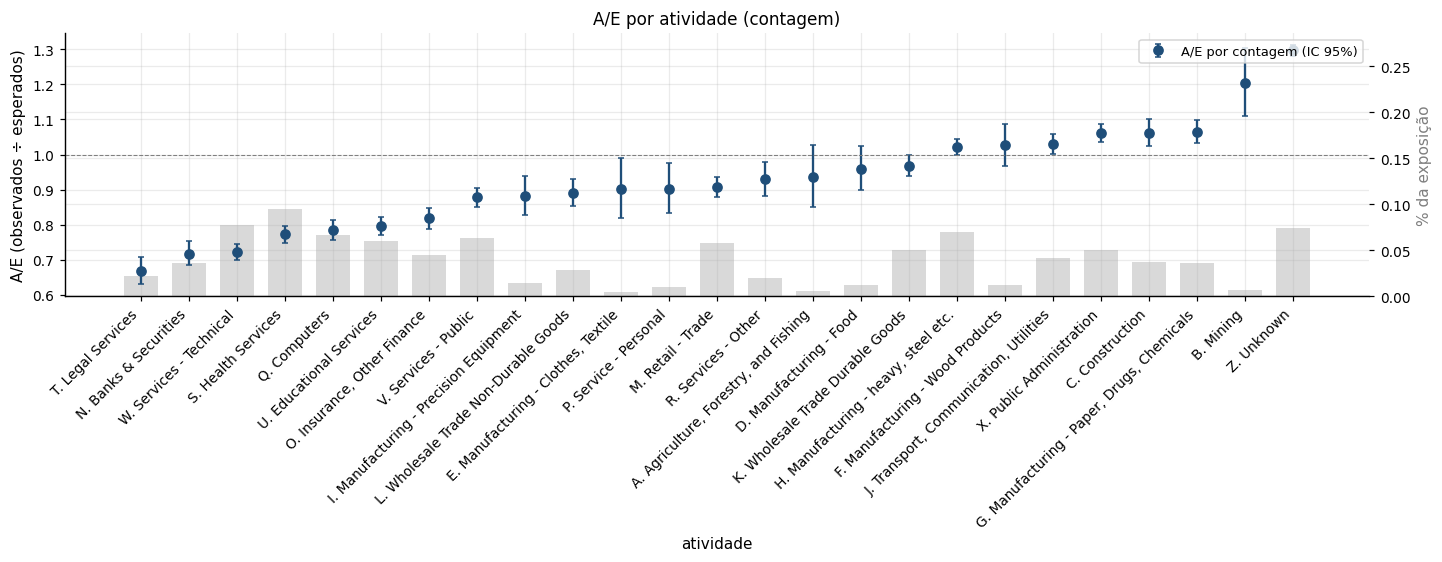

In [4]:
t = S.tabela_ae(soa, "atividade")
t = t[t["obitos"] >= 30].sort_values("ae").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(13, 5))
S.grafico_ae(ax, t, "atividade", "A/E por atividade (contagem)")
plt.show()

### A.3 Por que o A/E univariado não basta: capital e salário andam juntos

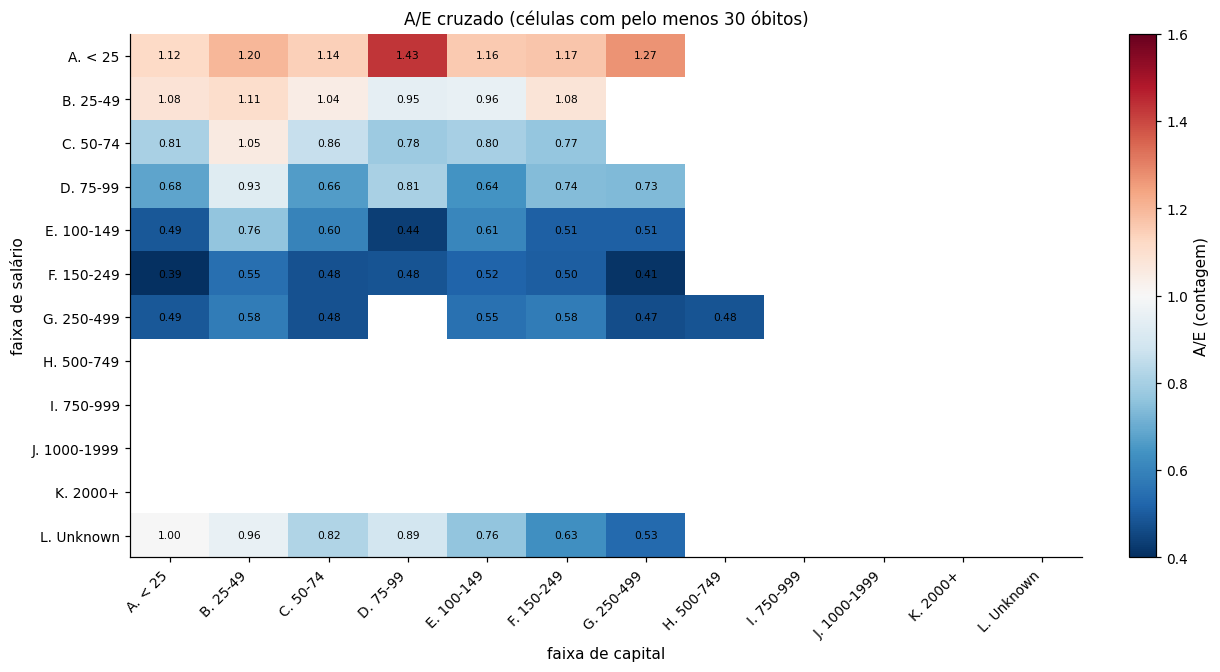

In [5]:
m = S.mapa_ae(soa, "faixa_salario", "faixa_capital", min_obitos=30)
fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(m.to_numpy(dtype=float), cmap="RdBu_r", vmin=0.4, vmax=1.6, aspect="auto")
ax.set_xticks(range(m.shape[1]), [str(c) for c in m.columns], rotation=45, ha="right")
ax.set_yticks(range(m.shape[0]), [str(i) for i in m.index]); ax.grid(False)
ax.set_xlabel("faixa de capital"); ax.set_ylabel("faixa de salário")
for i in range(m.shape[0]):
    for j in range(m.shape[1]):
        v = m.iloc[i, j]
        if pd.notna(v): ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, ax=ax, label="A/E (contagem)"); ax.set_title("A/E cruzado (células com pelo menos 30 óbitos)")
plt.show()

Dentro de uma mesma faixa de capital, o A/E ainda cai com o salário (e vice-versa): as duas variáveis
carregam informação própria, mas são correlacionadas. Somar os dois efeitos univariados contaria o mesmo efeito
duas vezes. Separar efeitos correlacionados é o trabalho do modelo multivariado (Etapa 3); o próprio relatório da
SOA aponta essa limitação dos estudos tradicionais.

### A.4 Nível da mortalidade: vida em grupo nos EUA × BR-EMSmt 2026

Só para contexto: a forma por idade é parecida, o nível não. Por isso nada do **nível** da SOA é usado no Brasil.

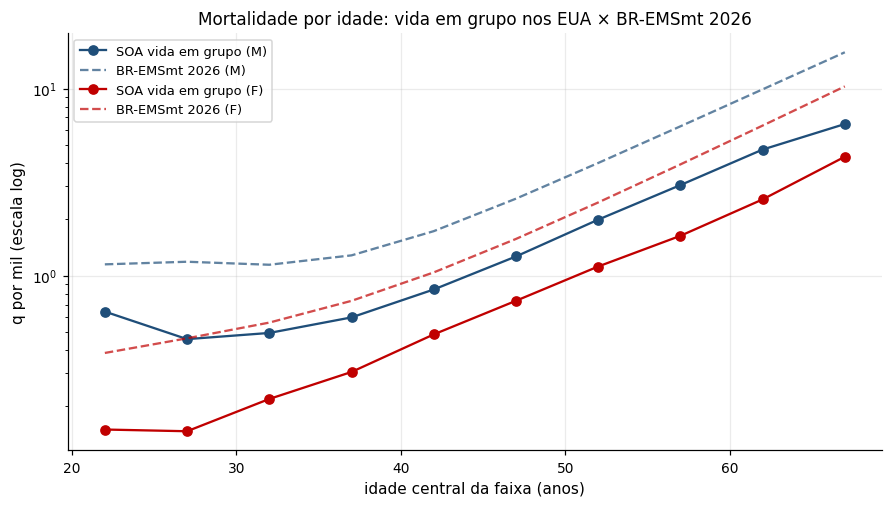

In [6]:
q = soa.groupby(["sexo", "idade_central"])[["obitos", "vidas_ano"]].sum()
q["q_soa"] = q["obitos"] / q["vidas_ano"]
q = q.reset_index()
q = q[(q["idade_central"] >= 22) & (q["idade_central"] <= 67)]
q["q_bremsmt"] = tabua.q(q["idade_central"].to_numpy(), q["sexo"].to_numpy())
fig, ax = plt.subplots(figsize=(8, 4.5))
for s, cor in (("M", "#1f4e79"), ("F", "#c00000")):
    d = q[q["sexo"] == s]
    ax.plot(d["idade_central"], 1000 * d["q_soa"], "o-", color=cor, label=f"SOA vida em grupo ({s})")
    ax.plot(d["idade_central"], 1000 * d["q_bremsmt"], "--", color=cor, alpha=0.7, label=f"BR-EMSmt 2026 ({s})")
ax.set_yscale("log"); ax.set_xlabel("idade central da faixa (anos)"); ax.set_ylabel("q por mil (escala log)")
ax.set_title("Mortalidade por idade: vida em grupo nos EUA × BR-EMSmt 2026"); ax.legend()
plt.show()

## B. Mercado brasileiro (SUSEP SES, dados reais)

Sinistralidade = sinistro ocorrido ÷ prêmio ganho, ramo 0993 (vida). Atenção: inclui todas as coberturas do
ramo e é medida contra o prêmio carregado; não é um A/E de mortalidade. A série começa em 2014, quando a SUSEP
passou a publicar o sinistro ocorrido (antes, o campo era outro e não é comparável).

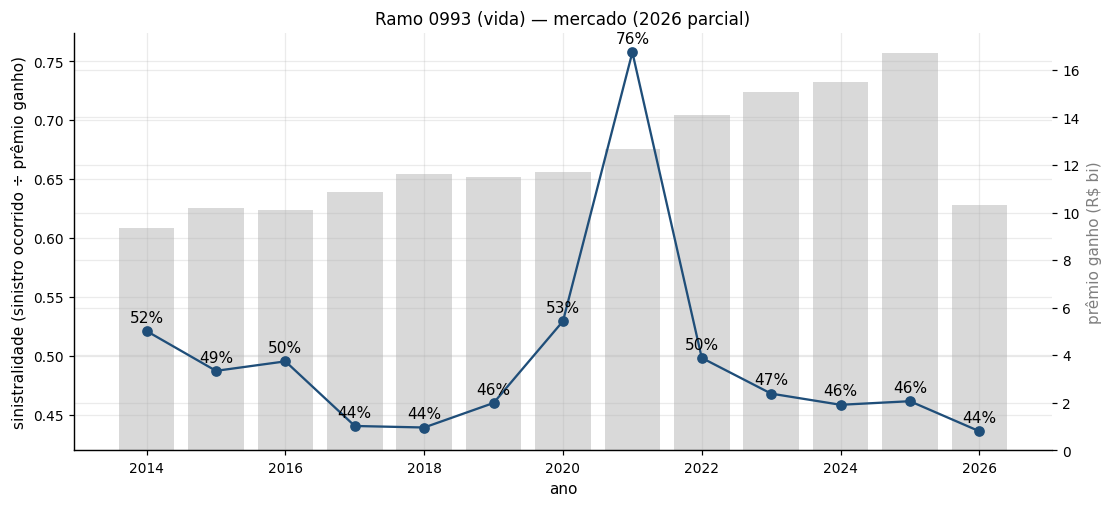

,premio_ganho,sinistro,sinistralidade,comissao_sobre_pg
ano,,,,
2014,"9,329,916,984.200","4,860,802,244.420",0.521,0.260
2015,"10,203,546,820.747","4,971,372,758.200",0.487,0.260
2016,"10,088,920,520.310","4,996,757,342.465",0.495,0.275
2017,"10,863,057,103.166","4,784,326,090.475",0.440,0.281
2018,"11,641,775,204.471","5,112,241,381.672",0.439,0.280
2019,"11,502,236,093.429","5,290,625,695.119",0.460,0.289
2020,"11,705,909,947.753","6,196,848,656.463",0.529,0.279
2021,"12,671,810,716.304","9,600,062,222.301",0.758,0.277
2022,"14,109,765,417.038","7,029,447,148.263",0.498,0.281


In [7]:
m = P.sinistralidade_anual(ses, "0993")
ano_max = ses["ano"].max()
fig, ax = plt.subplots(figsize=(10, 4.5)); ax2 = ax.twinx()
ax2.bar(m["ano"], m["premio_ganho"] / 1e9, color="#d9d9d9", zorder=0); ax2.set_ylabel("prêmio ganho (R$ bi)", color="#7f7f7f")
ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
ax.plot(m["ano"], m["sinistralidade"], "o-", color="#1f4e79")
ax.set_xlabel("ano"); ax.set_ylabel("sinistralidade (sinistro ocorrido ÷ prêmio ganho)")
ax.set_title(f"Ramo 0993 (vida) — mercado ({ano_max} parcial)")
for _, r in m.iterrows(): ax.annotate(f"{r['sinistralidade']:.0%}", (r["ano"], r["sinistralidade"]), textcoords="offset points", xytext=(0, 6), ha="center")
plt.show()
m.set_index("ano")[["premio_ganho", "sinistro", "sinistralidade", "comissao_sobre_pg"]]

**Leitura:** fora da pandemia, a sinistralidade do mercado fica estável perto de 45%–50%; em 2021 sobe para
cerca de 76%. É evidência brasileira direta de que **anos pandêmicos precisam de tratamento explícito** no estudo
de experiência e no backtest (excluir, ajustar ou manter, como política documentada).

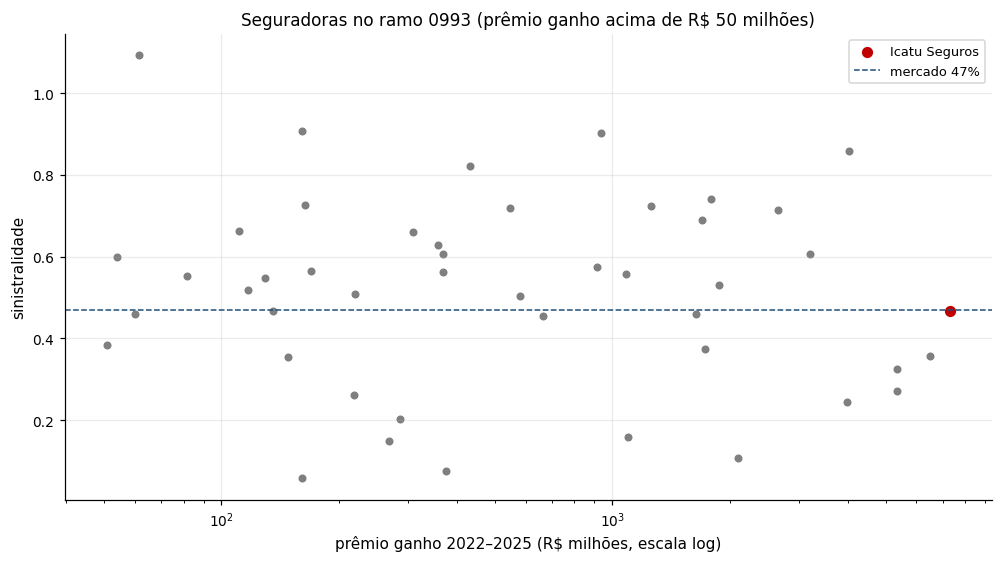

46 seguradoras; sinistralidade entre 6% e 109%


In [8]:
ult = ses[ses["ano"].between(2022, ano_max - 1)]
c = P.sinistralidade_anual(ult, "0993", por_cia=True).groupby(["coenti", "noenti"], as_index=False)[["premio_ganho", "sinistro"]].sum()
c = c[c["premio_ganho"] > 5e7]
c["sinistralidade"] = c["sinistro"] / c["premio_ganho"]
media = c["sinistro"].sum() / c["premio_ganho"].sum()
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(c["premio_ganho"] / 1e6, c["sinistralidade"], s=18, color="#7f7f7f")
icatu = c[c["noenti"].str.contains("ICATU", na=False)]
ax.scatter(icatu["premio_ganho"] / 1e6, icatu["sinistralidade"], s=40, color="#c00000", label="Icatu Seguros")
ax.axhline(media, color="#1f4e79", ls="--", lw=1, label=f"mercado {media:.0%}")
ax.set_xscale("log"); ax.set_xlabel(f"prêmio ganho 2022–{ano_max - 1} (R$ milhões, escala log)"); ax.set_ylabel("sinistralidade")
ax.set_title("Seguradoras no ramo 0993 (prêmio ganho acima de R$ 50 milhões)"); ax.legend()
plt.show()
print(f"{len(c)} seguradoras; sinistralidade entre {c['sinistralidade'].min():.0%} e {c['sinistralidade'].max():.0%}")

A dispersão é maior entre seguradoras pequenas: com menos prêmio, há menos credibilidade. É a mesma lógica da
renovação de um grupo, em outra escala, e por isso esta base serve para testar a credibilidade com dados reais
(Etapa 6). As diferenças entre seguradoras misturam mortalidade, carregamento, mix de coberturas e de produtos:
não são diferenças de risco puras.

## C. Carteira da seguradora (sintética)

O mesmo estudo, sobre a carteira, contra a BR-EMSmt 2026. Na base real da Icatu este é o estudo anual.

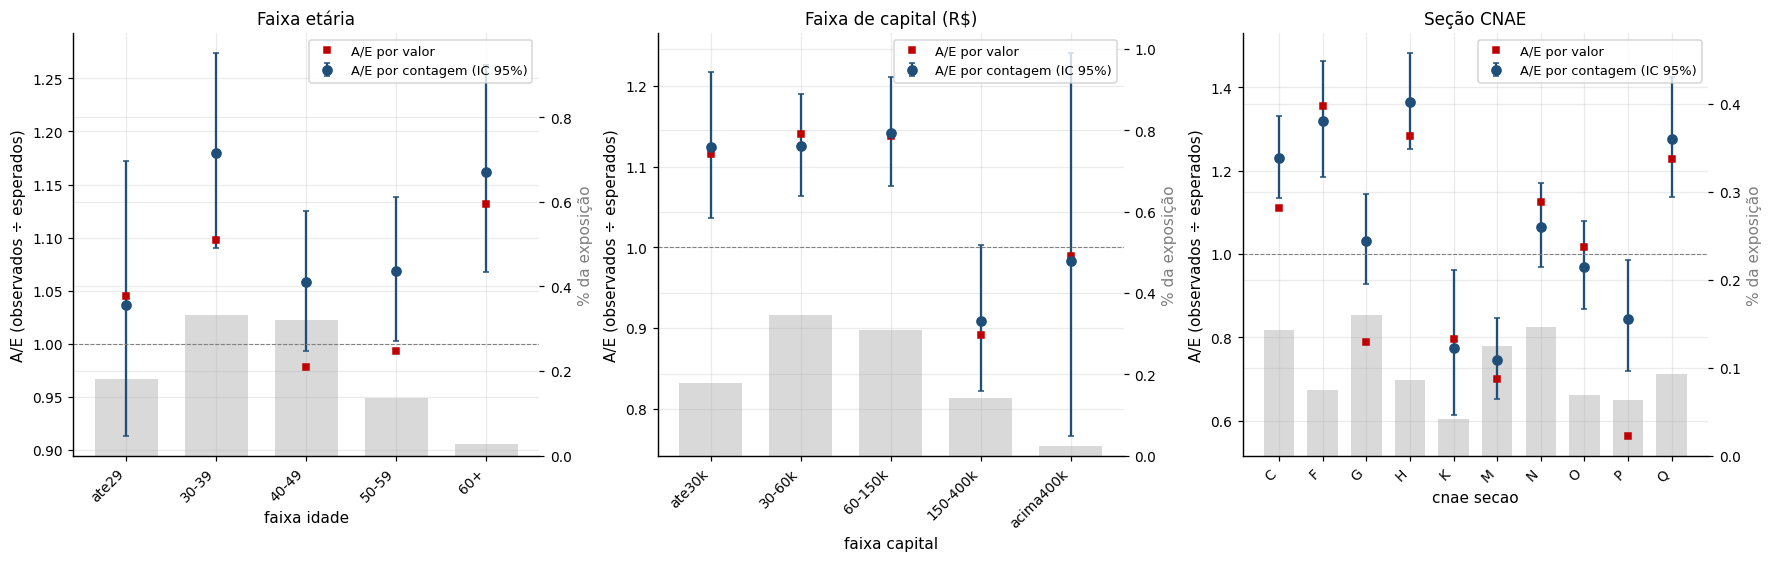

Experiência maturada até 2024-12-31: 3,430 óbitos, 3,127 esperados


In [9]:
pasta = RAIZ / cfg["pasta_processados"] / "limpo"
if not pasta.exists():
    raise FileNotFoundError("Rode antes o notebook 01_dados.")
d = {t: pd.read_parquet(pasta / f"{t}.parquet") for t in ("estipulantes", "vidas", "sinistros")}
cel, info = M.base_modelagem(d["vidas"], d["sinistros"], d["estipulantes"], tabua, cfg["data_referencia"], cm)
fig, axs = plt.subplots(1, 3, figsize=(16, 5))
for ax, (var, titulo) in zip(axs, [("faixa_idade", "Faixa etária"), ("faixa_capital", "Faixa de capital (R$)"), ("cnae_secao", "Seção CNAE")]):
    t = S.tabela_ae(cel, var, obs="N", esp="E", exposicao="exposicao", obs_valor="valor_observado", esp_valor="valor_esperado")
    if var != "cnae_secao":
        ordem = cm["faixas"]["idade" if var == "faixa_idade" else "capital"]["rotulos"]
        t = t.set_index(var).reindex(ordem).dropna(subset=["E"]).reset_index()
    S.grafico_ae(ax, t, var, titulo, col_valor=True)
plt.show()
print(f"Experiência maturada até {info['corte_experiencia']}: {info['obitos']:,} óbitos, {info['esperados']:,.0f} esperados")

Com poucos milhares de óbitos, os intervalos da carteira são muito mais largos que os da SOA: é exatamente por isso
que a taxa manual (Etapa 3) usa encolhimento e, onde a carteira não tem volume, a forma vinda do estudo de mercado.

## Limitações
- **SOA:** população americana, 2010–2013, classificação SIC, salário em dólar. Serve para a **forma** dos efeitos,
  não para o nível; o mapeamento para CNAE e para faixas em reais é julgamento documentado na Etapa 3.
- **SES:** dado agregado por seguradora, com carregamentos e todas as coberturas do ramo; não substitui o A/E.
- **Valor:** com dados agregados não há variância dos valores, então o A/E por valor aparece sem intervalo.